In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

df = pd.read_csv('KO_weekly_return_volatility.csv')
daily_data = pd.read_csv('KO_weekly_return_detailed.csv')

train = df[df['Year'].isin([2021, 2022, 2023])].reset_index(drop=True)
test = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)
daily_test = daily_data[daily_data['Year'].isin([2024, 2025])].reset_index(drop=True)

X_train = train[['mean_return', 'volatility']].values
Y_train = train['decision'].values
X_test = test[['mean_return', 'volatility']].values
Y_test = test['decision'].values

print(X_train.shape)



(156, 2)


## Q1 : For N=1..10 and d=1..5 compute error rates on training set and find best combination

N=1, d=1, error rate=35.26%
N=2, d=1, error rate=35.26%
N=3, d=1, error rate=35.26%
N=4, d=1, error rate=35.26%
N=5, d=1, error rate=35.26%
N=6, d=1, error rate=35.26%
N=7, d=1, error rate=35.26%
N=8, d=1, error rate=35.26%
N=9, d=1, error rate=35.26%
N=10, d=1, error rate=35.26%
N=1, d=2, error rate=42.31%
N=2, d=2, error rate=28.85%
N=3, d=2, error rate=28.85%
N=4, d=2, error rate=28.85%
N=5, d=2, error rate=34.62%
N=6, d=2, error rate=35.26%
N=7, d=2, error rate=28.85%
N=8, d=2, error rate=30.13%
N=9, d=2, error rate=29.49%
N=10, d=2, error rate=35.26%
N=1, d=3, error rate=31.41%
N=2, d=3, error rate=32.05%
N=3, d=3, error rate=32.05%
N=4, d=3, error rate=32.05%
N=5, d=3, error rate=32.69%
N=6, d=3, error rate=33.33%
N=7, d=3, error rate=31.41%
N=8, d=3, error rate=29.49%
N=9, d=3, error rate=29.49%
N=10, d=3, error rate=31.41%
N=1, d=4, error rate=31.41%
N=2, d=4, error rate=26.92%
N=3, d=4, error rate=28.85%
N=4, d=4, error rate=25.64%
N=5, d=4, error rate=26.92%
N=6, d=4, error r

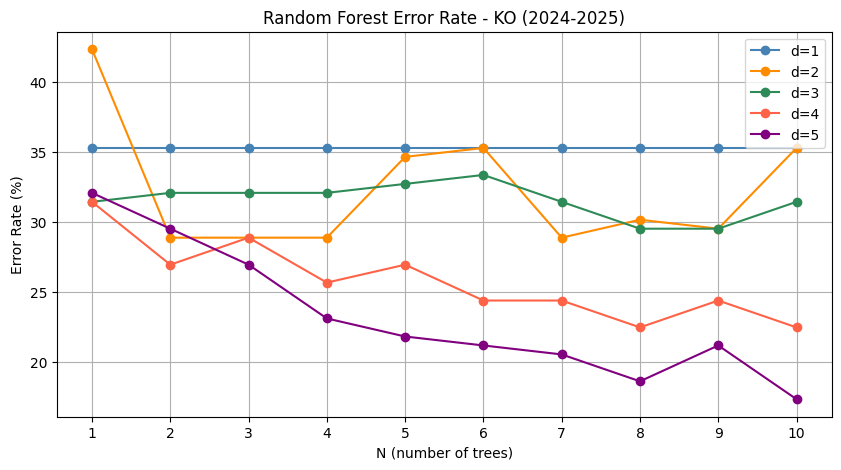


Best N=10, d=5, error rate=17.31%


In [6]:
# Q1: find best N and d by error rate on testing period
N_values = list(range(1, 11))
d_values = list(range(1, 6))
colors = ['steelblue', 'darkorange', 'seagreen', 'tomato', 'purple']

error_rates = {}
for d in d_values:
    errors = []
    for N in N_values:
        rf = RandomForestClassifier(n_estimators=N, max_depth=d, criterion='entropy', random_state=42)
        rf.fit(X_train, Y_train)
        error = round((1 - rf.score(X_train, Y_train)) * 100, 2)
        errors.append(error)
        print(f'N={N}, d={d}, error rate={error}%')
    error_rates[d] = errors

plt.figure(figsize=(10, 5))
for d, color in zip(d_values, colors):
    plt.plot(N_values, error_rates[d], marker='o', color=color, label=f'd={d}')
plt.xlabel('N (number of trees)')
plt.ylabel('Error Rate (%)')
plt.title('Random Forest Error Rate - KO (2024-2025)')
plt.xticks(N_values)
plt.legend()
plt.grid(True)
plt.savefig('rf_error_rates.png')
plt.show()

# find best N and d
best_N, best_d, best_error = 1, 1, 100
for d in d_values:
    for i, N in enumerate(N_values):
        if error_rates[d][i] < best_error:
            best_error = error_rates[d][i]
            best_N, best_d = N, d

print(f'\nBest N={best_N}, d={best_d}, error rate={best_error}%')

## Q2 : Confusion matrix for testing period using optimal N and d

In [10]:
# Q2: confusion matrix with best N and d
rf_best = RandomForestClassifier(n_estimators=best_N, max_depth=best_d, criterion='entropy', random_state=42)
rf_best.fit(X_train, Y_train)
preds = rf_best.predict(X_test)

cm = confusion_matrix(Y_test, preds, labels=['YES', 'NO'])
print('Confusion Matrix:')
print(f'  Predicted YES  Predicted NO')
print(f'Actual YES  {cm[0][0]}           {cm[0][1]}')
print(f'Actual NO   {cm[1][0]}           {cm[1][1]}')

Confusion Matrix:
  Predicted YES  Predicted NO
Actual YES  8           25
Actual NO   16           57


## Q3 : True positive rate and true negative rate

In [11]:
# Q3: TPR and TNR
TP, FN, FP, TN = cm[0][0], cm[0][1], cm[1][0], cm[1][1]
print(f'TPR (sensitivity): {round(TP / (TP + FN) * 100, 2)}%')
print(f'TNR (specificity): {round(TN / (TN + FP) * 100, 2)}%')

TPR (sensitivity): 24.24%
TNR (specificity): 78.08%


## Q4 : Trading strategy vs buy-and-hold

In [13]:
# Q4: trading strategy
test['rf_prediction'] = preds

initial_balance = 100
rf_balance = initial_balance
position = None

for week_idx in range(len(test)):
    current_week = test.iloc[week_idx]
    year = current_week['Year']
    week_num = current_week['Week_Number']
    week_data = daily_test[(daily_test['Year'] == year) & (daily_test['Week_Number'] == week_num)]

    if len(week_data) == 0:
        continue

    if position == 'invested':
        for idx, row in week_data.iterrows():
            if pd.notna(row['Return']):
                rf_balance = rf_balance * (1 + row['Return'] / 100)

    if week_idx < len(test) - 1:
        next_prediction = test.iloc[week_idx + 1]['rf_prediction']
        position = 'invested' if next_prediction == 'YES' else None

bh_balance = initial_balance
for idx, row in daily_test.iterrows():
    if pd.notna(row['Return']):
        bh_balance = bh_balance * (1 + row['Return'] / 100)

print(f'Random Forest Strategy Final Balance: ${rf_balance:.2f}')
print(f'Buy and Hold Final Balance: ${bh_balance:.2f}')
winner = 'Random Forest Strategy' if rf_balance > bh_balance else 'Buy-and-Hold'
print(f'{winner} results in a larger amount at the end of the testing period')

Random Forest Strategy Final Balance: $113.49
Buy and Hold Final Balance: $126.14
Buy-and-Hold results in a larger amount at the end of the testing period
